# Q11: Data Visualization using matplotlib

**Problem Statement:** Analyzing Air Quality Index (AQI) Trends in a City

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

air = pd.read_csv("City_Air_Quality.csv", parse_dates=["Date"])
print("Shape:", air.shape)
print(air.head().to_string(index=False))
print(air[["PM2.5", "PM10", "CO", "AQI"]].describe().round(2).to_string())


Shape: (150, 5)
      Date  PM2.5  PM10   CO  AQI
2025-01-01   42.1  76.3 1.25  120
2025-01-02   46.3  82.3 1.25  121
2025-01-03   32.1  71.7 0.99  101
2025-01-04   37.9  58.5 1.02  111
2025-01-05   41.5  53.5 1.03  119
        PM2.5    PM10      CO     AQI
count  150.00  150.00  150.00  150.00
mean    37.98   65.49    1.02  104.01
std     11.22   21.52    0.19   26.37
min     11.00   12.00    0.56   29.00
25%     29.35   51.70    0.89   86.00
50%     38.25   63.95    1.02  103.00
75%     45.70   80.68    1.17  123.75
max     64.30  111.00    1.49  162.00


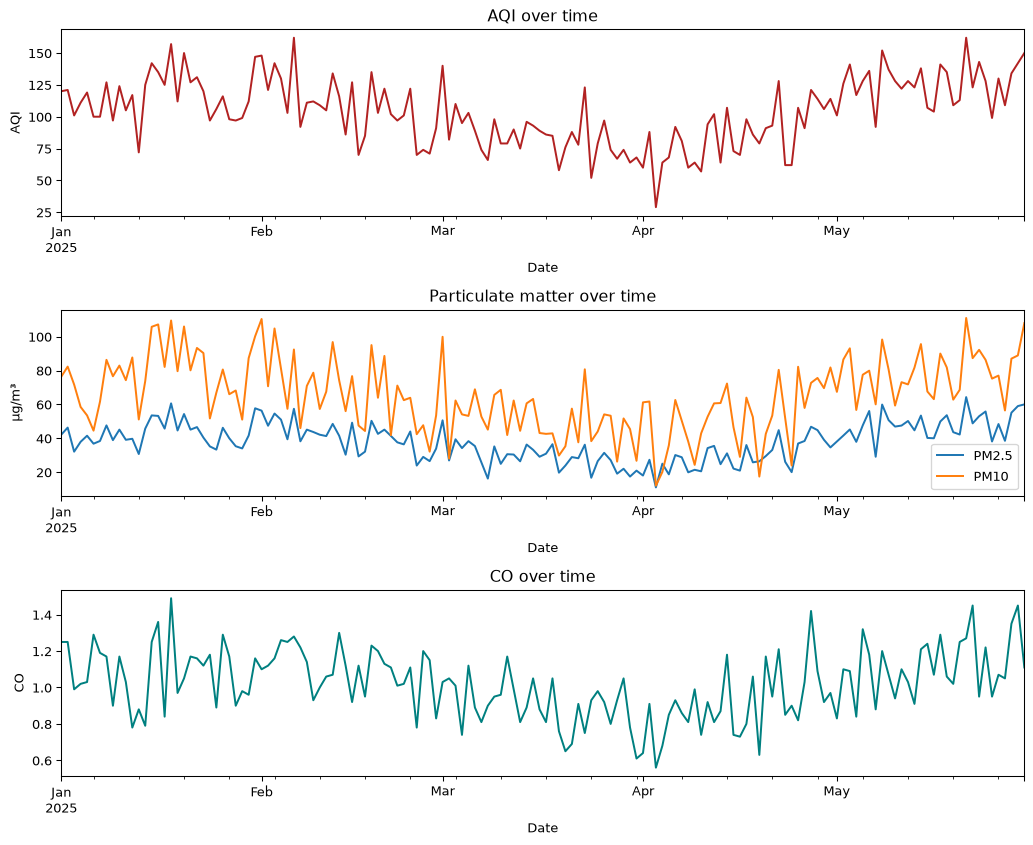

In [2]:
# Overall AQI time series and individual pollutant trends.
fig, axes = plt.subplots(3, 1, figsize=(11, 9))
air.plot(x="Date", y="AQI", ax=axes[0], legend=False, color="firebrick", title="AQI over time")
air.plot(x="Date", y=["PM2.5", "PM10"], ax=axes[1], title="Particulate matter over time")
air.plot(x="Date", y="CO", ax=axes[2], legend=False, color="teal", title="CO over time")
axes[0].set_ylabel("AQI")
axes[1].set_ylabel("µg/m³")
axes[2].set_ylabel("CO")
plt.tight_layout()
plt.show()


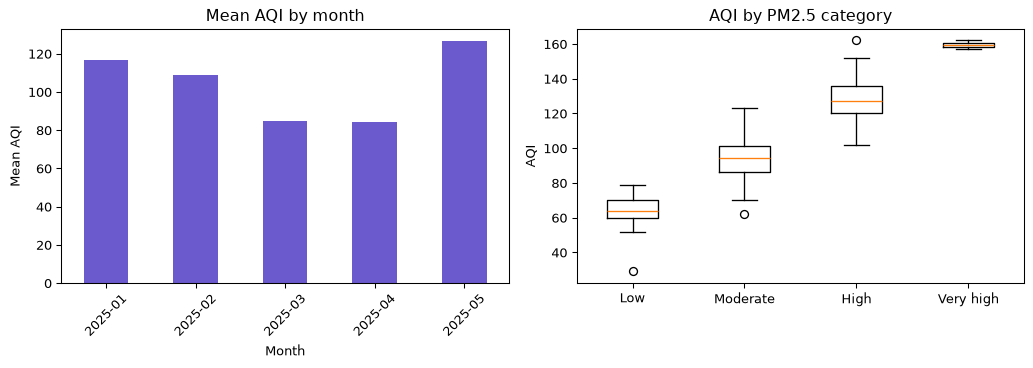

In [3]:
# Compare monthly AQI and AQI distributions across PM2.5 categories.
air["Month"] = air["Date"].dt.to_period("M").astype(str)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
air.groupby("Month")["AQI"].mean().plot.bar(ax=axes[0], color="slateblue", title="Mean AQI by month")
axes[0].set_ylabel("Mean AQI")
axes[0].tick_params(axis="x", rotation=45)
air["PM25Band"] = pd.cut(air["PM2.5"], bins=[0, 25, 40, 60, np.inf], labels=["Low", "Moderate", "High", "Very high"])
bands = [(label, air.loc[air["PM25Band"] == label, "AQI"]) for label in air["PM25Band"].cat.categories]
bands = [(label, values) for label, values in bands if not values.empty]
axes[1].boxplot([values for _, values in bands], tick_labels=[label for label, _ in bands])
axes[1].set_title("AQI by PM2.5 category")
axes[1].set_ylabel("AQI")
plt.tight_layout()
plt.show()


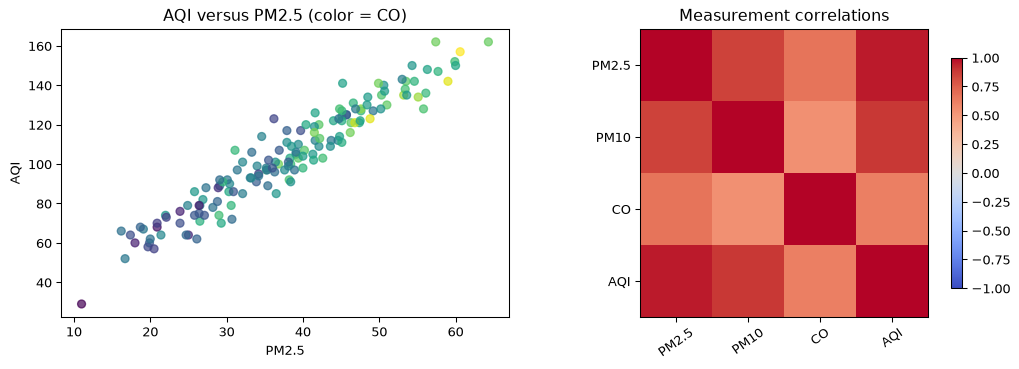

In [4]:
# Explore the relationship between particulate matter and AQI.
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(air["PM2.5"], air["AQI"], c=air["CO"], cmap="viridis", alpha=0.7)
axes[0].set(xlabel="PM2.5", ylabel="AQI", title="AQI versus PM2.5 (color = CO)")
correlation = air[["PM2.5", "PM10", "CO", "AQI"]].corr()
image = axes[1].imshow(correlation, cmap="coolwarm", vmin=-1, vmax=1)
axes[1].set_xticks(range(4), correlation.columns, rotation=35)
axes[1].set_yticks(range(4), correlation.columns)
axes[1].set_title("Measurement correlations")
fig.colorbar(image, ax=axes[1], shrink=0.8)
plt.tight_layout()
plt.show()
